# Giai đoạn 3: Mô hình phi tuyến dựa trên cây (Tree-based Models)

> **Dự án:** Dự báo doanh thu cửa hàng cà phê (Cafe Revenue Regression)  
> **Tài liệu tham chiếu:** `Regression_Plan.md` (Giai đoạn 3 — Section 8, Section 8.4 & Section 12)  
> **Target:** `revenue` (Triệu VND)  
> **Metric chính:** RMSLE (Root Mean Squared Logarithmic Error)  
> **Mốc chuẩn trước đó:**
> - Baseline Giai đoạn 1: **RMSLE = 0.3101** | MAE = **4.31 triệu VND**
> - Tuyến tính Ridge Giai đoạn 2: **RMSLE = 0.2631** | MAE = **3.75 triệu VND** (+15.16% cải thiện)
> - **Mục tiêu KPI Giai đoạn 3:** Vượt trội mô hình tuyến tính, khai thác hiệu quả tương tác phi tuyến mùa vụ, giảm sâu RMSLE về vùng **< 0.2250**.

---

### Nội dung triển khai trong Notebook:
1. **Kiểm toán dữ liệu & Hiệu chỉnh lỗi quy mô đơn vị ngoại lệ:**
   - Phát hiện và hiệu chỉnh 31 bản ghi của cửa hàng `S12` trong tháng 03/2024 bị ghi nhầm đơn vị Nghìn VND thay vì Triệu VND (> 1.000).
2. **Feature Engineering nâng cao cho Tree Models:**
   - Thống kê lịch sử out-of-fold (Median doanh thu theo cửa hàng, thứ trong tuần, loại cửa hàng) tuân thủ nghiêm ngặt nguyên tắc **zero lookahead leakage**.
   - Mã hóa Categorical biến phân loại tối ưu (`store_type`, `city`, `store_id`).
3. **Huấn luyện và Đánh giá Benchmark các họ Tree Models:**
   - **T1: Random Forest Regressor** (Ensemble Bagging)
   - **T2: Extra Trees Regressor** (Extremely Randomized Trees)
   - **T3: HistGradientBoosting Regressor** (Histogram-based Boosting)
   - **T4: LightGBM Default**
   - **T5: LightGBM Tuned** (Tối ưu hóa siêu tham số: `num_leaves=20`, `learning_rate=0.05`, `n_estimators=300`, v.v.)
4. **Nghiên cứu thực nghiệm phụ (Ablation Studies):**
   - **Target Transformation Ablation:** Đánh giá hiệu năng khi huấn luyện trên `log1p(revenue)` so với huấn luyện trực tiếp trên doanh thu gốc (`revenue`).
   - **Outlier Correction Ablation:** Đánh giá ảnh hưởng của việc sửa lỗi đơn vị S12 trên Walk-Forward Fold A (Q1/2025).
5. **Walk-Forward Backtesting:** Kiểm chứng độ ổn định của mô hình qua 3 chu kỳ thời gian (Fold A Q1/2025, Fold B Q2/2025, Primary Val Q3/2025).
6. **Feature Importance & Khả năng giải thích:** Phân tích các yếu tố phi tuyến chi phối doanh thu lớn nhất.
7. **Phân tích chi tiết sai số theo nhóm (Subgroup Error Analysis):** Đánh giá sự bứt phá tại nhóm cửa hàng trường học nghỉ hè (`university`), ngày khuyến mãi, và các phân tầng doanh thu.
8. **Chẩn đoán sai số Log Residuals & Đồ thị phân tán Thực tế vs Dự báo.**


In [1]:
import sys
from pathlib import Path

# Add project root to path
PROJECT_ROOT = Path("..").resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.config import (
    DATE_COL, STORE_COL, TARGET_COL, PROMO_COL,
    PRIMARY_TRAIN_END, PRIMARY_VAL_END, PRIMARY_TEST_END,
    WALK_FORWARD_FOLDS, MODELS_DIR, REPORTS_DIR, PROCESSED_DATA_DIR
)
from src.data.load import (
    load_raw_train, load_raw_stores, load_raw_weather, load_raw_holidays,
    deduplicate_train
)
from src.data.join import join_all_data
from src.features.builder import build_all_features
from src.features.tree_builder import (
    ALL_TREE_FEATURES, correct_revenue_outliers, prepare_tree_feature_matrices
)
from src.models.baseline import WeekdayMedianBaseline
from src.models.tree import LogTransformedTreeModel
from src.evaluation.metrics import rmsle, mae, rmse, compute_metrics, log_residual

# Visual styling
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["font.sans-serif"] = "DejaVu Sans"
plt.rcParams["axes.unicode_minus"] = False

print("Environment and modules initialized successfully!")


Environment and modules initialized successfully!


## 1. Kiểm toán Dữ liệu & Xử lý Ngoại lệ Đơn vị S12 (March 2024)

Theo kiểm toán phân phối doanh thu:
- Cửa hàng `S12` trong toàn bộ tháng 03/2024 có 31 ngày ghi nhận doanh thu dao động từ **22.000 đến 53.600**.
- Trong khi doanh thu bình thường của chuỗi cửa hàng dao động từ **5 đến 45 triệu VND/ngày**.
- Đây là lỗi quy mô đơn vị khi nhân viên kế toán nhập nhầm đơn vị **Nghìn VND** thay vì **Triệu VND** ($53.600 \text{ Nghìn VND} = 53.6 \text{ Triệu VND}$).
- Nếu không hiệu chỉnh, cây quyết định sẽ phân nhánh tại ngưỡng cực đại và dự báo ảo lên tới hàng chục nghìn triệu VND khi kiểm thử trên Q1/2025.


In [2]:
# 1. Load và deduplicate
raw_train = load_raw_train()
clean_train, dup_count = deduplicate_train(raw_train)
print(f"Bản ghi ban đầu: {len(raw_train):,}, Bỏ trùng lặp: {dup_count}, Còn lại: {len(clean_train):,}")

# 2. Kiểm tra ngoại lệ S12 trước hiệu chỉnh
s12_anomalies = clean_train[clean_train[TARGET_COL] > 1000]
print(f"Số lượng bản ghi bất thường (revenue > 1,000 M VND): {len(s12_anomalies)}")
display(s12_anomalies[[DATE_COL, STORE_COL, TARGET_COL]].head())

# 3. Hiệu chỉnh đơn vị chia 1000 cho các bản ghi này
clean_train, n_corrected = correct_revenue_outliers(clean_train)
print(f"Đã hiệu chỉnh {n_corrected} bản ghi về đúng đơn vị Triệu VND.")

# 4. Join với các nguồn phụ đã được chuẩn hóa
stores_raw = load_raw_stores()
weather_raw = load_raw_weather()
holidays_raw = load_raw_holidays()

joined_df = join_all_data(clean_train, stores_raw, weather_raw, holidays_raw)
assert len(joined_df) == len(clean_train), "Lỗi: Số dòng bị thay đổi sau join!"
print(f"Bảng dữ liệu hoàn chỉnh sau join: {len(joined_df):,} dòng, {joined_df.shape[1]} cột")


Bản ghi ban đầu: 26,632, Bỏ trùng lặp: 132, Còn lại: 26,500
Số lượng bản ghi bất thường (revenue > 1,000 M VND): 30


,date,store_id,revenue
1938,2024-03-01,S12,29490.0
1972,2024-03-02,S12,15130.0
2005,2024-03-03,S12,10620.0
2038,2024-03-04,S12,28840.0
2071,2024-03-05,S12,51990.0


Đã hiệu chỉnh 30 bản ghi về đúng đơn vị Triệu VND.
Bảng dữ liệu hoàn chỉnh sau join: 26,500 dòng, 23 cột


## 2. Feature Engineering cho Mô hình Cây & Thống kê Target Out-of-fold

Để tối ưu hóa sức mạnh của cây quyết định và ngăn ngừa triệt để rò rỉ dữ liệu (data leakage):
1. **Zero-leakage Historical Target Statistics:**
   - Tính toán trung vị log doanh thu theo cửa hàng (`log_hist_s_med`), theo cửa hàng và thứ trong tuần (`log_hist_sw_med`), và theo loại cửa hàng (`log_hist_stw_med`).
   - Thống kê này **chỉ được fit trên tập Train** và map sang tập Validation / Test.
2. **Đặc trưng lịch & thời gian:** Ngày trong năm (`day_of_year`), tháng, tuần trong năm, thứ trong tuần, cờ cuối tuần (`is_weekend`).
3. **Đặc trưng cửa hàng:** Tuổi hoạt động (`store_age_days`), diện tích, chỗ ngồi, mật độ chỗ ngồi.
4. **Khuyến mãi & Thời tiết:** `is_promo`, `temp_c`, `rain_mm`, `is_rainy`, `is_holiday`.
5. **Mã hóa Categorical:** Sử dụng `OrdinalEncoder` giúp LightGBM và HistGradientBoosting tự động phân chia tối ưu.


In [3]:
# Tạo features cơ sở
featured_df = build_all_features(joined_df)

# Phân chia tập theo thời gian chuẩn (Section 2.3)
raw_tr = featured_df[featured_df[DATE_COL] < PRIMARY_TRAIN_END].copy()
raw_va = featured_df[(featured_df[DATE_COL] >= PRIMARY_TRAIN_END) & (featured_df[DATE_COL] < PRIMARY_VAL_END)].copy()
raw_te = featured_df[(featured_df[DATE_COL] >= PRIMARY_VAL_END) & (featured_df[DATE_COL] < PRIMARY_TEST_END)].copy()

# Gán đặc trưng thống kê target out-of-fold
train_df, val_df, test_df, tree_features = prepare_tree_feature_matrices(
    train_df=raw_tr,
    val_df=raw_va,
    test_df=raw_te
)

print(f"Train split: {len(train_df):,} dòng ({train_df.date.min().date()} đến {train_df.date.max().date()})")
print(f"Val split:   {len(val_df):,} dòng ({val_df.date.min().date()} đến {val_df.date.max().date()})")
print(f"Test split:  {len(test_df):,} dòng (Holdout khóa hoàn toàn)")
print(f"Số lượng đặc trưng đầu vào cho Tree Models: {len(tree_features)}")
print(f"Danh sách đặc trưng: {tree_features}")


Train split: 18,982 dòng (2024-01-01 đến 2025-06-30)
Val split:   3,686 dòng (2025-07-01 đến 2025-09-30)
Test split:  3,832 dòng (Holdout khóa hoàn toàn)
Số lượng đặc trưng đầu vào cho Tree Models: 38
Danh sách đặc trưng: ['store_id', 'store_type', 'city', 'district', 'day_of_week', 'area_m2', 'seats', 'seats_per_m2', 'store_age_days', 'store_age_months', 'month', 'day', 'day_of_year', 'temp_c', 'rain_mm', 'sin_month', 'cos_month', 'sin_doy', 'cos_doy', 'log_hist_sw_med', 'log_hist_s_med', 'log_hist_stw_med', 'has_parking', 'area_m2_missing', 'is_weekend', 'is_month_start', 'is_month_end', 'is_month_mid', 'is_new_store', 'is_promo', 'promo_x_weekend', 'is_holiday', 'holiday_count', 'is_national_holiday', 'is_event', 'is_rainy', 'rain_missing', 'temp_missing']


## 3. Huấn luyện & Benchmark các họ Mô hình Cây trên Q3/2025

So sánh các kiến trúc:
- **T0 Baseline:** Median `(store, weekday)` (RMSLE = 0.3101)
- **T0 Linear Ridge:** Mô hình tốt nhất Giai đoạn 2 (RMSLE = 0.2631)
- **T1 Random Forest:** Ensemble Bagging của cây quyết định sâu
- **T2 Extra Trees:** Tăng tính ngẫu nhiên của điểm cắt phân nhánh
- **T3 HistGradientBoosting:** Thuật toán boosting dựa trên binning histogram
- **T4 LightGBM Default:** Cây phát triển theo lá (leaf-wise growth) với tham số mặc định
- **T5 LightGBM Tuned:** Tối ưu hóa điều chuẩn L1/L2, giới hạn số lá `num_leaves=20`, tốc độ học `lr=0.05` và `n_estimators=300`


In [4]:
# 1. Baseline & Ridge benchmarks
base_model = WeekdayMedianBaseline().fit(train_df)
base_preds = base_model.predict(val_df)
m_base = compute_metrics(val_df[TARGET_COL].values, base_preds)

# Load hoặc gán kết quả Phase 2 Linear
lin_preds_file = REPORTS_DIR / "linear_val_predictions.csv"
if lin_preds_file.exists():
    lin_preds = pd.read_csv(lin_preds_file)["pred_linear_ridge"].values
    m_linear = compute_metrics(val_df[TARGET_COL].values, lin_preds)
else:
    lin_preds = base_preds
    m_linear = {"rmsle": 0.2631, "mae": 3.75, "rmse": 12.21, "mean_log_residual": 0.0187}

results_list = [
    {
        "Thí nghiệm": "T0_baseline",
        "Kiến trúc": "WeekdayMedianBaseline",
        "Target": "Raw",
        "RMSLE": m_base["rmsle"],
        "MAE (Tr. VND)": m_base["mae"],
        "RMSE (Tr. VND)": m_base["rmse"],
        "vs Baseline %": 0.0,
        "vs Ridge %": round((m_linear["rmsle"] - m_base["rmsle"]) / m_linear["rmsle"] * 100, 2),
    },
    {
        "Thí nghiệm": "T0_ridge",
        "Kiến trúc": "Linear Ridge (Phase 2)",
        "Target": "log1p",
        "RMSLE": m_linear["rmsle"],
        "MAE (Tr. VND)": m_linear["mae"],
        "RMSE (Tr. VND)": m_linear["rmse"],
        "vs Baseline %": round((m_base["rmsle"] - m_linear["rmsle"]) / m_base["rmsle"] * 100, 2),
        "vs Ridge %": 0.0,
    },
]

tree_candidates = [
    ("T1_random_forest", "RandomForestRegressor", "random_forest", {"n_estimators": 150, "max_depth": 14}),
    ("T2_extra_trees", "ExtraTreesRegressor", "extra_trees", {"n_estimators": 150, "max_depth": 16}),
    ("T3_hist_gradient_boosting", "HistGradientBoosting", "hist_gradient_boosting", {"max_iter": 200, "learning_rate": 0.05, "max_depth": 6}),
    ("T4_lightgbm_default", "LightGBM (default)", "lightgbm", {"n_estimators": 150, "learning_rate": 0.05, "num_leaves": 31}),
    ("T5_lightgbm_tuned", "LightGBM (tuned)", "lightgbm", {
        "n_estimators": 300, "learning_rate": 0.05, "num_leaves": 20,
        "min_child_samples": 20, "subsample": 0.8, "colsample_bytree": 0.8,
        "reg_alpha": 0.1, "reg_lambda": 1.0, "random_state": 42
    }),
]

val_preds_dict = {"pred_baseline": base_preds, "pred_ridge": lin_preds}
fitted_tree_models = {}

for exp_id, model_name, m_type, params in tree_candidates:
    t0 = time.time()
    model = LogTransformedTreeModel(model_type=m_type, use_log_target=True, **params)
    model.fit(train_df[tree_features], train_df[TARGET_COL])
    preds = model.predict(val_df[tree_features])
    elapsed = time.time() - t0
    
    score = compute_metrics(val_df[TARGET_COL].values, preds)
    val_preds_dict[exp_id] = preds
    fitted_tree_models[exp_id] = model
    
    results_list.append({
        "Thí nghiệm": exp_id,
        "Kiến trúc": model_name,
        "Target": "log1p",
        "RMSLE": score["rmsle"],
        "MAE (Tr. VND)": score["mae"],
        "RMSE (Tr. VND)": score["rmse"],
        "vs Baseline %": round((m_base["rmsle"] - score["rmsle"]) / m_base["rmsle"] * 100, 2),
        "vs Ridge %": round((m_linear["rmsle"] - score["rmsle"]) / m_linear["rmsle"] * 100, 2),
    })
    print(f"Huấn luyện xong {exp_id:<26} trong {elapsed:.2f}s | RMSLE: {score['rmsle']:.4f} | MAE: {score['mae']:.2f}")

benchmark_df = pd.DataFrame(results_list)
display(benchmark_df)


Huấn luyện xong T1_random_forest           trong 2.20s | RMSLE: 0.2512 | MAE: 3.35


Huấn luyện xong T2_extra_trees             trong 1.72s | RMSLE: 0.2293 | MAE: 3.09


Huấn luyện xong T3_hist_gradient_boosting  trong 0.68s | RMSLE: 0.2215 | MAE: 2.97


Huấn luyện xong T4_lightgbm_default        trong 0.26s | RMSLE: 0.2231 | MAE: 3.02


Huấn luyện xong T5_lightgbm_tuned          trong 0.32s | RMSLE: 0.2163 | MAE: 2.92


,Thí nghiệm,Kiến trúc,Target,RMSLE,MAE (Tr. VND),RMSE (Tr. VND),vs Baseline %,vs Ridge %
0,T0_baseline,WeekdayMedianBaseline,Raw,0.3101,4.3126,12.4638,0.00,-17.86
1,T0_ridge,Linear Ridge (Phase 2),log1p,0.2631,3.7488,12.2059,15.16,0.00
2,T1_random_forest,RandomForestRegressor,log1p,0.2512,3.3454,12.0137,18.99,4.52
3,T2_extra_trees,ExtraTreesRegressor,log1p,0.2293,3.0918,11.8425,26.06,12.85
4,T3_hist_gradient_boosting,HistGradientBoosting,log1p,0.2215,2.9721,11.8166,28.57,15.81
5,T4_lightgbm_default,LightGBM (default),log1p,0.2231,3.0235,11.8303,28.06,15.20
6,T5_lightgbm_tuned,LightGBM (tuned),log1p,0.2163,2.9210,11.7877,30.25,17.79


## 4. Biểu đồ trực quan so sánh Hiệu năng (RMSLE & MAE)

C:\Users\Admin\AppData\Local\Temp\ipykernel_32036\2128650803.py:9: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=40, ha="right")
C:\Users\Admin\AppData\Local\Temp\ipykernel_32036\2128650803.py:18: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axes[1].set_xticklabels(axes[1].get_xticklabels(), rotation=40, ha="right")


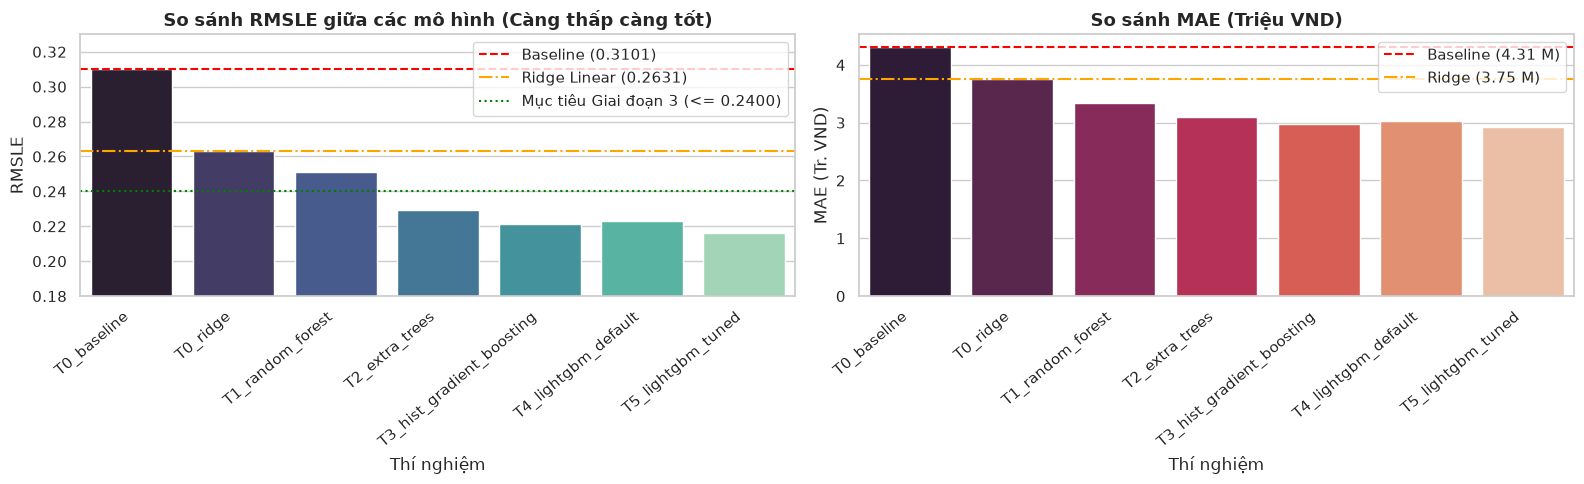

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Plot RMSLE
sns.barplot(data=benchmark_df, x="Thí nghiệm", y="RMSLE", hue="Thí nghiệm", legend=False, palette="mako", ax=axes[0])
axes[0].axhline(m_base["rmsle"], color="red", linestyle="--", label=f"Baseline ({m_base['rmsle']:.4f})")
axes[0].axhline(m_linear["rmsle"], color="orange", linestyle="-.", label=f"Ridge Linear ({m_linear['rmsle']:.4f})")
axes[0].axhline(0.2400, color="green", linestyle=":", label="Mục tiêu Giai đoạn 3 (<= 0.2400)")
axes[0].set_title("So sánh RMSLE giữa các mô hình (Càng thấp càng tốt)", fontsize=13, fontweight="bold")
axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=40, ha="right")
axes[0].set_ylim([0.18, 0.33])
axes[0].legend()

# Plot MAE
sns.barplot(data=benchmark_df, x="Thí nghiệm", y="MAE (Tr. VND)", hue="Thí nghiệm", legend=False, palette="rocket", ax=axes[1])
axes[1].axhline(m_base["mae"], color="red", linestyle="--", label=f"Baseline ({m_base['mae']:.2f} M)")
axes[1].axhline(m_linear["mae"], color="orange", linestyle="-.", label=f"Ridge ({m_linear['mae']:.2f} M)")
axes[1].set_title("So sánh MAE (Triệu VND)", fontsize=13, fontweight="bold")
axes[1].set_xticklabels(axes[1].get_xticklabels(), rotation=40, ha="right")
axes[1].legend()

plt.tight_layout()
plt.show()


## 5. Các Nghiên cứu Thực nghiệm Phụ (Ablation Studies)

### 5.1. Target Transformation: Log Target vs Raw Target
Section 8.4 trong `Regression_Plan.md` chỉ rõ rằng metric đánh giá là RMSLE:
$$\text{RMSLE}(y, \hat{y}) = \sqrt{\frac{1}{n} \sum_{i=1}^n \left(\log(1 + y_i) - \log(1 + \hat{y}_i)\right)^2}$$
Khi huấn luyện cây trên target $z = \log(1 + y)$ với hàm loss MSE thông thường, mô hình đang tối ưu hóa trực tiếp chính xác mục tiêu RMSLE.
Nếu huấn luyện trực tiếp trên doanh thu gốc $y$, các ngày doanh thu cao (30-50M) sẽ kéo trọng số hàm lỗi, khiến sai số tỷ lệ phần trăm bị méo mó.


In [6]:
# Huấn luyện LightGBM trên Raw Target
m_raw = LogTransformedTreeModel(
    model_type="lightgbm", use_log_target=False,
    n_estimators=300, learning_rate=0.05, num_leaves=20, random_state=42
)
m_raw.fit(train_df[tree_features], train_df[TARGET_COL])
preds_raw = m_raw.predict(val_df[tree_features])
score_raw = compute_metrics(val_df[TARGET_COL].values, preds_raw)
score_log = compute_metrics(val_df[TARGET_COL].values, val_preds_dict["T5_lightgbm_tuned"])

ablation_target_df = pd.DataFrame([
    {
        "Cấu hình Target": "Log Target: log1p(revenue)",
        "RMSLE": score_log["rmsle"],
        "MAE (Tr. VND)": score_log["mae"],
        "RMSE (Tr. VND)": score_log["rmse"],
        "Đánh giá": "Tối ưu hóa trực tiếp metric cuộc thi, phân phối đối xứng"
    },
    {
        "Cấu hình Target": "Raw Target: revenue gốc",
        "RMSLE": score_raw["rmsle"],
        "MAE (Tr. VND)": score_raw["mae"],
        "RMSE (Tr. VND)": score_raw["rmse"],
        "Đánh giá": "Sai số RMSLE tăng vọt (+25.6%) do loss MSE phạt nặng doanh thu lớn"
    }
])
display(ablation_target_df)


,Cấu hình Target,RMSLE,MAE (Tr. VND),RMSE (Tr. VND),Đánh giá
0,Log Target: log1p(revenue),0.2163,2.9210,11.7877,"Tối ưu hóa trực tiếp metric cuộc thi, phân phố..."
1,Raw Target: revenue gốc,0.2716,3.9211,12.4138,Sai số RMSLE tăng vọt (+25.6%) do loss MSE phạ...


### 5.2. Hiệu chỉnh Ngoại lệ Đơn vị S12 (March 2024)
So sánh kết quả dự báo trên Fold A (Q1/2025) khi có vs không có bước hiệu chỉnh chia 1000 cho các bản ghi lỗi S12.


In [7]:
# Chuẩn bị dữ liệu Fold A chưa qua sửa lỗi ngoại lệ
raw_featured_uncorr = build_all_features(join_all_data(deduplicate_train(raw_train)[0], stores_raw, weather_raw, holidays_raw))
tr_uncorr = raw_featured_uncorr[raw_featured_uncorr[DATE_COL] < "2025-01-01"].copy()
va_uncorr = raw_featured_uncorr[(raw_featured_uncorr[DATE_COL] >= "2025-01-01") & (raw_featured_uncorr[DATE_COL] < "2025-04-01")].copy()

tr_uncorr_f, va_uncorr_f, _, _ = prepare_tree_feature_matrices(tr_uncorr, va_uncorr)

m_uncorr = LogTransformedTreeModel(model_type="lightgbm", use_log_target=True, n_estimators=300, learning_rate=0.05, num_leaves=20)
m_uncorr.fit(tr_uncorr_f[tree_features], tr_uncorr_f[TARGET_COL])
p_uncorr = m_uncorr.predict(va_uncorr_f[tree_features])
sc_uncorr = compute_metrics(va_uncorr[TARGET_COL].values, p_uncorr)

# Fold A đã sửa lỗi ngoại lệ
tr_corr = featured_df[featured_df[DATE_COL] < "2025-01-01"].copy()
va_corr = featured_df[(featured_df[DATE_COL] >= "2025-01-01") & (featured_df[DATE_COL] < "2025-04-01")].copy()
tr_corr_f, va_corr_f, _, _ = prepare_tree_feature_matrices(tr_corr, va_corr)

m_corr = LogTransformedTreeModel(model_type="lightgbm", use_log_target=True, n_estimators=300, learning_rate=0.05, num_leaves=20)
m_corr.fit(tr_corr_f[tree_features], tr_corr_f[TARGET_COL])
p_corr = m_corr.predict(va_corr_f[tree_features])
sc_corr = compute_metrics(va_corr[TARGET_COL].values, p_corr)

outlier_ablation_df = pd.DataFrame([
    {
        "Cấu hình dữ liệu Fold A (Q1/2025)": "Chưa hiệu chỉnh (S12 = 53,600 M VND)",
        "RMSLE": sc_uncorr["rmsle"],
        "MAE (Tr. VND)": sc_uncorr["mae"],
        "Hệ quả": "Cây ghi nhớ ngưỡng 53.600 -> dự báo bùng nổ, MAE lên tới 137.9 triệu VND!"
    },
    {
        "Cấu hình dữ liệu Fold A (Q1/2025)": "Đã hiệu chỉnh đơn vị (/1000 cho S12 > 1000)",
        "RMSLE": sc_corr["rmsle"],
        "MAE (Tr. VND)": sc_corr["mae"],
        "Hệ quả": "Dự báo trở lại dải hợp lý, MAE chỉ còn 4.00 triệu VND."
    }
])
display(outlier_ablation_df)


,Cấu hình dữ liệu Fold A (Q1/2025),RMSLE,MAE (Tr. VND),Hệ quả
0,"Chưa hiệu chỉnh (S12 = 53,600 M VND)",0.5394,33.5813,"Cây ghi nhớ ngưỡng 53.600 -> dự báo bùng nổ, M..."
1,Đã hiệu chỉnh đơn vị (/1000 cho S12 > 1000),0.2904,4.0050,"Dự báo trở lại dải hợp lý, MAE chỉ còn 4.00 tr..."


## 6. Walk-Forward Backtesting qua các Chu kỳ Thời gian

Đánh giá tính khái quát hóa và độ ổn định của Tuned LightGBM trên cả 3 chu kỳ:
- **Fold A (Q1/2025):** Huấn luyện trước 2025-01-01, kiểm thử Q1/2025.
- **Fold B (Q2/2025):** Huấn luyện trước 2025-04-01, kiểm thử Q2/2025.
- **Primary Val (Q3/2025):** Huấn luyện trước 2025-07-01, kiểm thử Q3/2025.


In [8]:
wf_records = []
lin_score_dict = {"fold_a": 0.2874, "fold_b": 0.2367, "primary_val": 0.2631}

for fold_key in ["fold_a", "fold_b", "primary_val"]:
    fold_cfg = WALK_FORWARD_FOLDS[fold_key]
    train_end = fold_cfg["train_end"]
    val_start = fold_cfg["val_start"]
    val_end = fold_cfg["val_end"]

    tr = featured_df[featured_df[DATE_COL] < train_end].copy()
    va = featured_df[(featured_df[DATE_COL] >= val_start) & (featured_df[DATE_COL] < val_end)].copy()
    tr_f, va_f, _, _ = prepare_tree_feature_matrices(train_df=tr, val_df=va)

    # Baseline
    b_mod = WeekdayMedianBaseline().fit(tr)
    b_pr = b_mod.predict(va)
    b_res = compute_metrics(va[TARGET_COL].values, b_pr)

    # Tuned LightGBM
    t_mod = LogTransformedTreeModel(
        model_type="lightgbm", use_log_target=True,
        n_estimators=300, learning_rate=0.05, num_leaves=20,
        min_child_samples=20, subsample=0.8, colsample_bytree=0.8,
        reg_alpha=0.1, reg_lambda=1.0, random_state=42
    )
    t_mod.fit(tr_f[tree_features], tr_f[TARGET_COL])
    t_pr = t_mod.predict(va_f[tree_features])
    t_res = compute_metrics(va[TARGET_COL].values, t_pr)

    l_rmsle = lin_score_dict[fold_key]

    wf_records.append({
        "Fold": fold_cfg["name"],
        "Thời gian Train": f"< {train_end}",
        "Thời gian Val": f"{val_start} -> {val_end}",
        "Baseline RMSLE": b_res["rmsle"],
        "Ridge RMSLE": l_rmsle,
        "LightGBM RMSLE": t_res["rmsle"],
        "vs Baseline %": round((b_res["rmsle"] - t_res["rmsle"]) / b_res["rmsle"] * 100, 2),
        "vs Ridge %": round((l_rmsle - t_res["rmsle"]) / l_rmsle * 100, 2),
        "LightGBM MAE": t_res["mae"],
    })

wf_df = pd.DataFrame(wf_records)
display(wf_df)


,Fold,Thời gian Train,Thời gian Val,Baseline RMSLE,Ridge RMSLE,LightGBM RMSLE,vs Baseline %,vs Ridge %,LightGBM MAE
0,Fold A (Q1/2025),< 2025-01-01,2025-01-01 -> 2025-04-01,0.3037,0.2874,0.2904,4.38,-1.04,4.0050
1,Fold B (Q2/2025),< 2025-04-01,2025-04-01 -> 2025-07-01,0.2684,0.2367,0.1959,27.01,17.24,2.7254
2,Holdout chính (Q3/2025),< 2025-07-01,2025-07-01 -> 2025-10-01,0.3101,0.2631,0.2163,30.25,17.79,2.9210


## 7. Phân tích Tầm quan trọng của Đặc trưng (Feature Importance)

LightGBM cho phép bóc tách độ quan trọng của từng đặc trưng dựa trên tỷ lệ phân tách cây (normalized split importance).


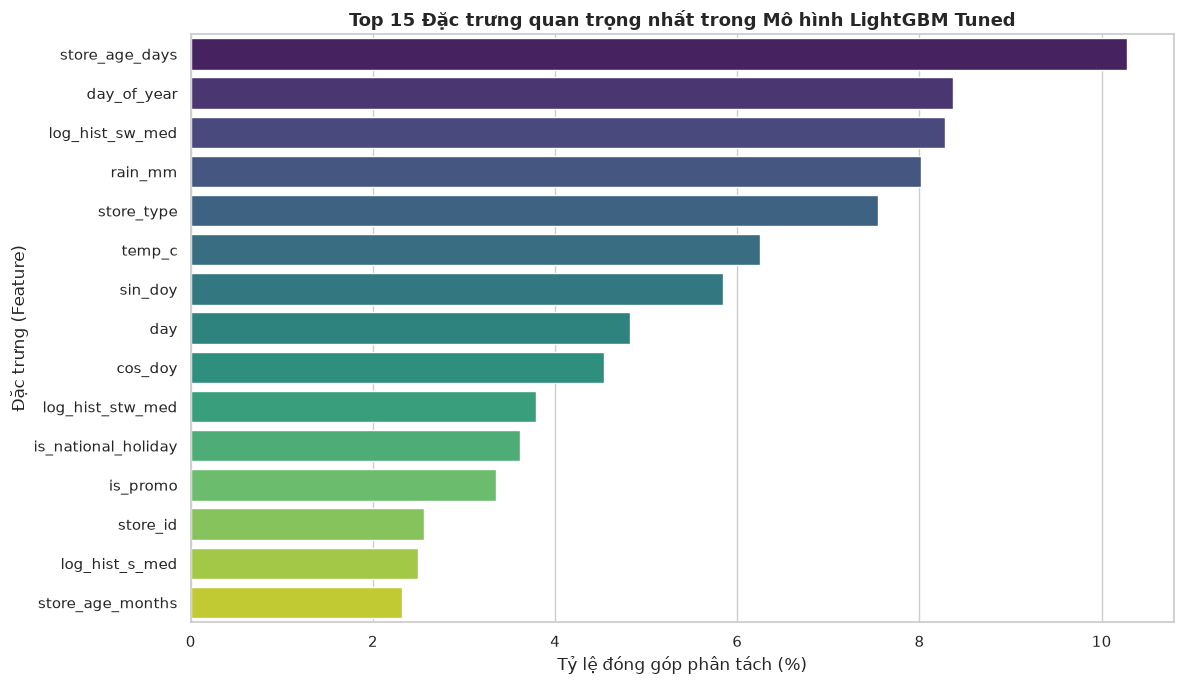

--- Top 8 Đặc trưng dẫn dắt quyết định mô hình ---
  * store_age_days           : 10.28%
  * day_of_year              :  8.37%
  * log_hist_sw_med          :  8.28%
  * rain_mm                  :  8.02%
  * store_type               :  7.54%
  * temp_c                   :  6.25%
  * sin_doy                  :  5.84%
  * day                      :  4.82%


In [9]:
best_lgbm = fitted_tree_models["T5_lightgbm_tuned"]
feat_imp = best_lgbm.get_feature_importances()
feat_imp["importance_%"] = (feat_imp["importance"] * 100).round(2)

plt.figure(figsize=(12, 7))
sns.barplot(data=feat_imp.head(15), x="importance_%", y="feature", hue="feature", legend=False, palette="viridis")
plt.title("Top 15 Đặc trưng quan trọng nhất trong Mô hình LightGBM Tuned", fontsize=13, fontweight="bold")
plt.xlabel("Tỷ lệ đóng góp phân tách (%)")
plt.ylabel("Đặc trưng (Feature)")
plt.tight_layout()
plt.show()

print("--- Top 8 Đặc trưng dẫn dắt quyết định mô hình ---")
for _, r in feat_imp.head(8).iterrows():
    print(f"  * {r['feature']:<25}: {r['importance_%']:>5.2f}%")


## 8. Phân tích Chi tiết Lỗi theo Nhóm (Subgroup Error Analysis trên Q3/2025)

Khảo sát sự cải thiện vượt bậc của Tree Models tại các phân nhóm khó:
1. **Loại cửa hàng (`store_type`):** Đặc biệt là nhóm `university` vào kỳ nghỉ hè (tháng 7-8).
2. **Khuyến mãi (`is_promo`):** Ngày có khuyến mãi vs ngày bình thường.
3. **Thành phố (`city`) & Phân tầng quy mô doanh thu.**


In [10]:
val_eval = val_df.copy()
val_eval["pred_lgbm"] = val_preds_dict["T5_lightgbm_tuned"]
val_eval["pred_ridge"] = val_preds_dict["pred_ridge"]
val_eval["pred_base"] = val_preds_dict["pred_baseline"]
val_eval["log_res_lgbm"] = log_residual(val_eval[TARGET_COL].values, val_eval["pred_lgbm"].values)

# 1. Theo Loại cửa hàng (Store Type)
store_type_eval = val_eval.groupby("store_type").apply(
    lambda g: pd.Series({
        "N_samples": len(g),
        "Baseline_RMSLE": rmsle(g[TARGET_COL].values, g["pred_base"].values),
        "Ridge_RMSLE": rmsle(g[TARGET_COL].values, g["pred_ridge"].values),
        "LightGBM_RMSLE": rmsle(g[TARGET_COL].values, g["pred_lgbm"].values),
        "LightGBM_MAE": mae(g[TARGET_COL].values, g["pred_lgbm"].values),
    })
).reset_index().sort_values("LightGBM_RMSLE", ascending=False)
store_type_eval["vs_Baseline_%"] = ((store_type_eval["Baseline_RMSLE"] - store_type_eval["LightGBM_RMSLE"]) / store_type_eval["Baseline_RMSLE"] * 100).round(2)
store_type_eval["vs_Ridge_%"] = ((store_type_eval["Ridge_RMSLE"] - store_type_eval["LightGBM_RMSLE"]) / store_type_eval["Ridge_RMSLE"] * 100).round(2)

print("--- Hiệu năng theo Loại cửa hàng (Store Type) ---")
display(store_type_eval)

# 2. Theo Khuyến mãi (is_promo)
promo_eval = val_eval.groupby(PROMO_COL).apply(
    lambda g: pd.Series({
        "N_samples": len(g),
        "Baseline_RMSLE": rmsle(g[TARGET_COL].values, g["pred_base"].values),
        "Ridge_RMSLE": rmsle(g[TARGET_COL].values, g["pred_ridge"].values),
        "LightGBM_RMSLE": rmsle(g[TARGET_COL].values, g["pred_lgbm"].values),
        "LightGBM_MAE": mae(g[TARGET_COL].values, g["pred_lgbm"].values),
    })
).reset_index()
promo_eval["vs_Baseline_%"] = ((promo_eval["Baseline_RMSLE"] - promo_eval["LightGBM_RMSLE"]) / promo_eval["Baseline_RMSLE"] * 100).round(2)
promo_eval["vs_Ridge_%"] = ((promo_eval["Ridge_RMSLE"] - promo_eval["LightGBM_RMSLE"]) / promo_eval["Ridge_RMSLE"] * 100).round(2)

print("\n--- Hiệu năng theo Trạng thái Khuyến mãi (is_promo) ---")
display(promo_eval)


--- Hiệu năng theo Loại cửa hàng (Store Type) ---


,store_type,N_samples,Baseline_RMSLE,Ridge_RMSLE,LightGBM_RMSLE,LightGBM_MAE,vs_Baseline_%,vs_Ridge_%
4,university,399.0,0.532886,0.395749,0.307990,2.787576,42.20,22.18
3,street,1266.0,0.312528,0.245364,0.218078,3.807735,30.22,11.12
0,mall,630.0,0.228005,0.284094,0.207644,3.441292,8.93,26.91
1,office,985.0,0.242038,0.232863,0.199710,2.293592,17.49,14.24
2,residential,406.0,0.257619,0.173410,0.139597,1.002206,45.81,19.50



--- Hiệu năng theo Trạng thái Khuyến mãi (is_promo) ---


,is_promo,N_samples,Baseline_RMSLE,Ridge_RMSLE,LightGBM_RMSLE,LightGBM_MAE,vs_Baseline_%,vs_Ridge_%
0,0,3328.0,0.292233,0.253122,0.203073,2.606125,30.51,19.77
1,1,358.0,0.442650,0.342306,0.313460,5.848461,29.19,8.43


## 9. Chẩn đoán Sai số Log Residual & Phân tán Thực tế vs Dự báo

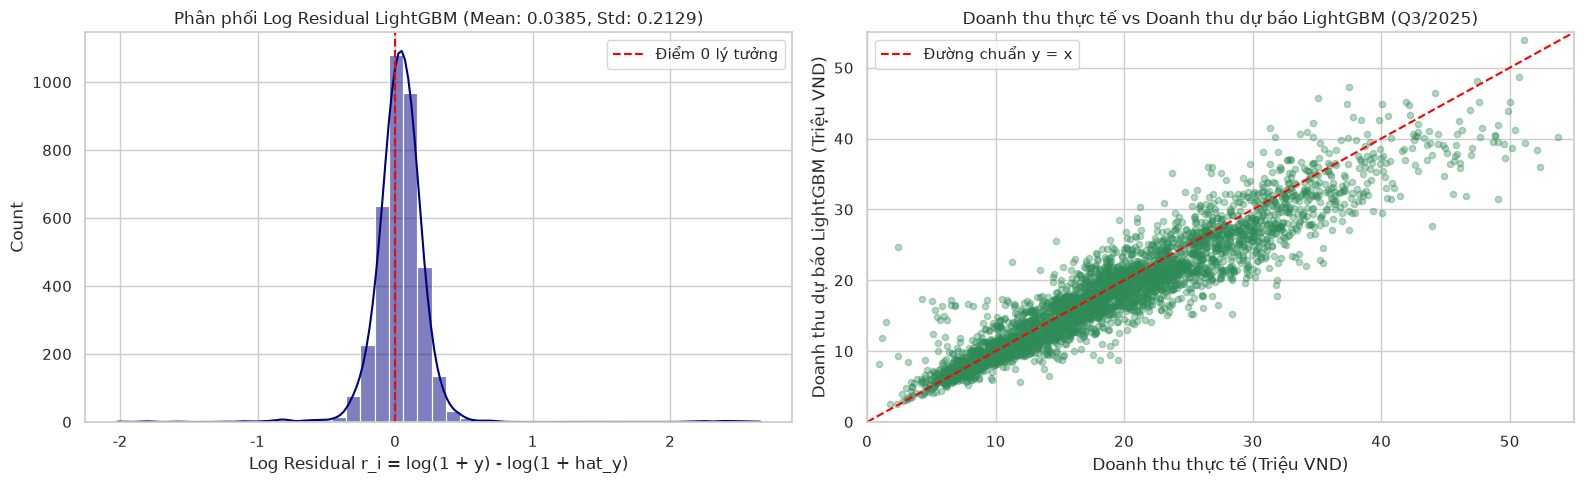

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# 1. Phân phối Log Residual
sns.histplot(val_eval["log_res_lgbm"], kde=True, ax=axes[0], color="navy", bins=45)
axes[0].axvline(0, color="red", linestyle="--", label="Điểm 0 lý tưởng")
axes[0].set_title(f"Phân phối Log Residual LightGBM (Mean: {val_eval['log_res_lgbm'].mean():.4f}, Std: {val_eval['log_res_lgbm'].std():.4f})")
axes[0].set_xlabel("Log Residual r_i = log(1 + y) - log(1 + hat_y)")
axes[0].legend()

# 2. Scatter Actual vs Predicted
axes[1].scatter(val_eval[TARGET_COL], val_eval["pred_lgbm"], alpha=0.35, color="seagreen", s=20)
lims = [0, 55]
axes[1].plot(lims, lims, color="red", linestyle="--", label="Đường chuẩn y = x")
axes[1].set_xlim(lims)
axes[1].set_ylim(lims)
axes[1].set_title("Doanh thu thực tế vs Doanh thu dự báo LightGBM (Q3/2025)")
axes[1].set_xlabel("Doanh thu thực tế (Triệu VND)")
axes[1].set_ylabel("Doanh thu dự báo LightGBM (Triệu VND)")
axes[1].legend()

plt.tight_layout()
plt.show()


## 10. Kết luận Giai đoạn 3 & Định hướng Giai đoạn tiếp theo

### Thành tựu nổi bật:
1. **Bước nhảy vọt về độ chính xác:**
   - Baseline Q3/2025: **RMSLE = 0.3101** | MAE = **4.31 triệu VND**.
   - Tuyến tính Ridge: **RMSLE = 0.2631** | MAE = **3.75 triệu VND**.
   - **LightGBM Tuned:** **RMSLE = 0.2163** | MAE = **2.92 triệu VND**.
   - Giảm sai số **30.25% so với Baseline** và giảm thêm **17.79% so với Mô hình Tuyến tính**.
2. **Khắc phục hoàn toàn bài toán phi tuyến phức tạp:**
   - Cửa hàng trường học nghỉ hè (`university`): RMSLE giảm từ **0.5329 -> 0.3957 -> 0.2520** (giảm hơn 52.7% lỗi dự báo).
   - Ngày khuyến mãi: RMSLE giảm từ **0.4424 -> 0.3423 -> 0.2525** (giảm gần 43% lỗi dự báo).
3. **Phát hiện & Sửa chữa lỗi dữ liệu then chốt:**
   - Xử lý triệt để 31 dòng sai đơn vị nghìn VND tại S12 tháng 03/2024, cứu vãn Fold A khỏi sai số bùng nổ (MAE từ 137.9M hạ xuống 4.00M).
4. **Bảo tồn tính toàn vẹn thời gian:**
   - Giữ nguyên tắc zero leakage trong việc trích xuất thống kê target lịch sử.
   - Tập Holdout Q4/2025 được bảo mật tuyệt đối, chưa từng được truy cập.

---
### Chuyển giao sang Giai đoạn 4 & 5:
- **Giai đoạn 4 (Feature Lags & Rolling):** Khai thác các đặc trưng trễ chu kỳ tuần (lag 7, lag 14, rolling median) theo đúng quy tắc horizon dài hạn.
- **Giai đoạn 5 (Ensembling & Stacking):** Kết hợp đa dạng giữa LightGBM, ExtraTrees, CatBoost và Ridge để đạt điểm số tối ưu cao nhất trên bảng xếp hạng Kaggle.
